In [1]:
#Importo pandas para abrir el df
import pandas as pd

In [2]:
# Carga de datos desde Google Drive
FILE_ID = '1xtfIVuyOoayCfLOyAOe4jfZ2wOwpPs9R'
url = f'https://drive.google.com/uc?id={FILE_ID}'

# Los datos provienen de las ediciones 2011-2012 y 2013-2014 de NHANES (Encuesta Nacional de Examen de Salud y Nutrición) de EEUU.
# La base está curada, se transformaron variables y se seleccionaron las de interés.

# Leemos el archivo directamente a un DataFrame de Pandas
try:
    df = pd.read_csv(url)
    print(f"Dataset cargado con éxito. Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas.")
    display(df.head())
except Exception as e:
    print(f"Error al cargar el archivo: {e}. Verifica el ID o los permisos de Drive.")

Dataset cargado con éxito. Dimensiones: 6045 filas y 6 columnas.


,RIAGENDR,RIDAGEYR,BMXWT,BMXHT,MGX_MAXHT,DXD_ASM_BMI_LOW
0,1,22,69.2,172.3,34.9,0
1,2,44,67.2,170.1,38.3,0
2,1,21,54.6,164.8,47.4,0
3,2,43,98.6,172.0,35.5,0
4,1,55,91.4,182.1,60.6,0


In [3]:
#Veo el dataset
#RIAGENDR: género. 	RIDAGEYR: edad (años) 	BMXWT: peso (kg) 	BMXHT: altura (cm) 	MGX_MAXHT: maxima fuerza de prensión (kgf) 	DXD_ASM_BMI_LOW: baja masa muscular
df

,RIAGENDR,RIDAGEYR,BMXWT,BMXHT,MGX_MAXHT,DXD_ASM_BMI_LOW
0,1,22,69.2,172.3,34.9,0
1,2,44,67.2,170.1,38.3,0
2,1,21,54.6,164.8,47.4,0
3,2,43,98.6,172.0,35.5,0
4,1,55,91.4,182.1,60.6,0
...,...,...,...,...,...,...
6040,1,58,76.3,170.4,43.9,0
6041,1,52,79.5,176.2,47.9,0
6042,1,40,79.0,171.7,46.4,0
6043,1,26,71.8,171.3,37.2,0


In [4]:
#Busco valores nulos
df.isnull().sum()

RIAGENDR           0
RIDAGEYR           0
BMXWT              0
BMXHT              0
MGX_MAXHT          0
DXD_ASM_BMI_LOW    0
dtype: int64

In [5]:
variables = ["RIAGENDR", "RIDAGEYR","BMXWT","BMXHT","MGX_MAXHT","DXD_ASM_BMI_LOW"]
valores_unicos = {col: df[col].unique() for col in variables}
print(valores_unicos)

{'RIAGENDR': array([1, 2]), 'RIDAGEYR': array([22, 44, 21, 43, 55, 35, 26, 57, 42, 36, 28, 31, 41, 32, 54, 19, 48,
       23, 58, 24, 34, 18, 47, 52, 27, 29, 33, 30, 56, 46, 38, 50, 40, 20,
       53, 49, 39, 59, 51, 37, 45, 25]), 'BMXWT': array([ 69.2,  67.2,  54.6,  98.6,  91.4,  89. ,  68.9,  96.9,  73.7,
        80.2,  84.8,  70.9, 113.1, 145.2,  80.1,  55.4,  72.2,  84.1,
        90.1,  97. ,  76.9,  99.4,  57.4,  82.7,  53.6,  83.1,  53.3,
        72.3,  99.3, 131.6,  68.4,  73. ,  57.2,  67.5,  62.4,  75. ,
       124.5,  64.1,  91.9, 120.7,  87.8, 101.9,  78.8,  86.7,  50.4,
       117.1, 112.7,  77. ,  94.4,  77.6,  91.3,  76.7,  80.3, 106. ,
        58.7,  64.2,  76.2,  51.8,  65.3, 130.5,  90.6,  91.1, 117.6,
        56.2,  78.9,  74.6, 100.4,  66.3,  97.9,  76. ,  73.2,  67.7,
        66.1,  53.1,  58.4,  96.8,  96.4, 117.9,  68.2,  80.4,  88.4,
       129.4,  79.6,  85.3,  61.1,  96.2,  75.3,  75.8, 126.5, 106.1,
        79. ,  77.1,  56.4,  63.3, 118.8,  62.9,  63.7, 101.

In [6]:
print(df[variables].nunique())

RIAGENDR             2
RIDAGEYR            42
BMXWT              976
BMXHT              484
MGX_MAXHT          527
DXD_ASM_BMI_LOW      2
dtype: int64


In [7]:
# Defino mis variables RIAGENDR y DXD_ASM_BMI_LOW son categoricas, ya que tienen solo 2 valores que pueden ser binomiales. Las otras son continuas.

df['RIAGENDR'] = df['RIAGENDR'].astype('category')
df['DXD_ASM_BMI_LOW'] = df['DXD_ASM_BMI_LOW'].astype('category')

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 6045 entries, 0 to 6044
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   RIAGENDR         6045 non-null   category
 1   RIDAGEYR         6045 non-null   int64   
 2   BMXWT            6045 non-null   float64 
 3   BMXHT            6045 non-null   float64 
 4   MGX_MAXHT        6045 non-null   float64 
 5   DXD_ASM_BMI_LOW  6045 non-null   category
dtypes: category(2), float64(3), int64(1)
memory usage: 200.9 KB
None


In [8]:
#Defino covariables(X) y variable objetivo (Y)
y = df['DXD_ASM_BMI_LOW']
x = df.drop('DXD_ASM_BMI_LOW', axis=1)          #Al poner drop ignora del conjunto predictor a tu varaible que queres predecir, en este caso DXD_AMD

In [9]:
#Importo las librerias necesarias
from sklearn.model_selection import train_test_split, GridSearchCV       #PARA TUNING DE PARAMETROS
from sklearn.linear_model import LogisticRegression                      #Modelo de regresion
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix        #Metricas de rendimiento
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Divido en entrenaminto y testeo (80% - 20%)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)     #Test size indica que guarde 20% aleatorio para testearlo

In [10]:
#Veo las 5 primeras filas de mi grupo de entrenamiento
print("x_train - Primeras 5 filas:")
print(x_train.head())
print("\nx_train - Tamaño:")
print(x_train.shape)

print("\ny_train - Primeras 5 filas:")
print(y_train.head())
print("\ny_train - Tamaño:")
print(y_train.shape)

x_train - Primeras 5 filas:
     RIAGENDR  RIDAGEYR  BMXWT  BMXHT  MGX_MAXHT
5678        2        26   64.7  155.4       32.2
3945        1        24   65.9  174.5       46.0
1094        1        57  104.5  174.4       41.5
1121        1        25  107.2  169.7       34.3
1770        1        23   99.8  171.1       44.7

x_train - Tamaño:
(4836, 5)

y_train - Primeras 5 filas:
5678    0
3945    0
1094    0
1121    1
1770    0
Name: DXD_ASM_BMI_LOW, dtype: category
Categories (2, int64): [0, 1]

y_train - Tamaño:
(4836,)


In [11]:
#Veo las 5 primeras filas de mi grupo de testeo
print("x_test - Primeras 5 filas:")
print(x_test.head())
print("\nx_test - Tamaño:")
print(x_test.shape)

print("\ny_test - Primeras 5 filas:")
print(y_test.head())
print("\ny_test - Tamaño:")
print(y_test.shape)

x_test - Primeras 5 filas:
     RIAGENDR  RIDAGEYR  BMXWT  BMXHT  MGX_MAXHT
2505        2        18   77.0  167.3       33.5
4603        1        19   47.9  165.2       33.6
1992        1        33   94.8  172.4       53.1
1918        1        31   71.8  172.4       55.9
5466        2        38   69.6  164.5       34.0

x_test - Tamaño:
(1209, 5)

y_test - Primeras 5 filas:
2505    0
4603    0
1992    0
1918    0
5466    0
Name: DXD_ASM_BMI_LOW, dtype: category
Categories (2, int64): [0, 1]

y_test - Tamaño:
(1209,)


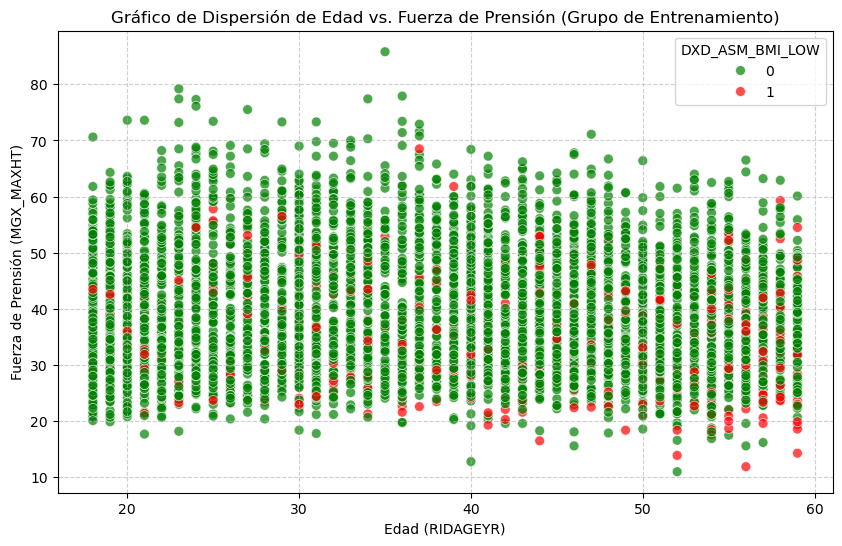

In [12]:
#Quiero ver un gráfico de dispersión de mi grupo de entrenamiento cruzando fuerza y edad
train_df = pd.concat([x_train, y_train], axis=1)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=train_df,
    x='RIDAGEYR', # Edad
    y='MGX_MAXHT', # Fuerza de prensión
    hue='DXD_ASM_BMI_LOW',
    palette={0: 'green', 1: 'red'},
    s=50, # Tamaño de los puntos
    alpha=0.7 # Transparencia
)

plt.title('Gráfico de Dispersión de Edad vs. Fuerza de Prensión (Grupo de Entrenamiento)')
plt.xlabel('Edad (RIDAGEYR)')
plt.ylabel('Fuerza de Prensión (MGX_MAXHT)')
plt.legend(title='DXD_ASM_BMI_LOW')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [13]:
#IMPORTANTE: Para regresion logistica debo estandarizar las variables continuas (llevar la media 0 y desviación estándar 1)
from sklearn.preprocessing import StandardScaler

#Inicio la funcion para escalar
scaler = StandardScaler()

# Identifico las columnas numéricas a estandarizar (excluyendo 'RIAGENDR')
numerical_cols = ['RIDAGEYR', 'BMXWT', 'BMXHT', 'MGX_MAXHT']
categorical_cols = ['RIAGENDR']

# Escalo las variables numéricas de entrenamiento
x_train_scaled_numerical = scaler.fit_transform(x_train[numerical_cols])

# Escalo las variables numéricas de testeo (por separado)
x_test_scaled_numerical = scaler.transform(x_test[numerical_cols])

# Convierto los arrays escalados a DataFrame y mantengo los nombres de las columnas e índices
x_train_scaled_numerical = pd.DataFrame(x_train_scaled_numerical, columns=numerical_cols, index=x_train.index)
x_test_scaled_numerical = pd.DataFrame(x_test_scaled_numerical, columns=numerical_cols, index=x_test.index)

# Reintegro la columna 'RIAGENDR' (categórica) a los datasets escalados
x_train_scaled = pd.concat([x_train[categorical_cols], x_train_scaled_numerical], axis=1)
x_test_scaled = pd.concat([x_test[categorical_cols], x_test_scaled_numerical], axis=1)


print("x_train_scaled - Primeras 5 filas:")
print(x_train_scaled.head())
print("\nx_test_scaled - Primeras 5 filas:")
print(x_test_scaled.head())

x_train_scaled - Primeras 5 filas:
     RIAGENDR  RIDAGEYR     BMXWT     BMXHT  MGX_MAXHT
5678        2 -0.896050 -0.759975 -1.365334  -0.662918
3945        1 -1.056736 -0.703606  0.623588   0.568339
1094        1  1.594581  1.109596  0.613175   0.166842
1121        1 -0.976393  1.236426  0.123755  -0.475553
1770        1 -1.137079  0.888817  0.269539   0.452351

x_test_scaled - Primeras 5 filas:
     RIAGENDR  RIDAGEYR     BMXWT     BMXHT  MGX_MAXHT
2505        2 -1.538793 -0.182193 -0.126162  -0.546930
4603        1 -1.458450 -1.549140 -0.344840  -0.538008
1992        1 -0.333649  0.653947  0.404911   1.201811
1918        1 -0.494335 -0.426458  0.404911   1.451631
5466        2  0.068066 -0.529801 -0.417732  -0.502319


En lugar de simplemente "correr el modelo", estás realizando una búsqueda sistemática (Grid Search) para encontrar la mejor configuración posible.
Esta es la parte más potente del código. GridSearchCV hace tres cosas a la vez:

Combinatoria: Prueba cada valor de C con cada tipo de penalty (6 valores de C × 2 penalidades = 12 modelos distintos).

Validación Cruzada (cv=5): Divide tus datos de entrenamiento en 5 partes. Entrena 12 veces por cada parte para asegurarse de que el resultado sea estable y no por "suerte".

Optimización por F1-Score: Le ordenas que el ganador sea el modelo que tenga mejor F1-Score (el equilibrio entre precisión y sensibilidad), lo cual es ideal en medicina.

El código calcula un arsenal de métricas para evaluar qué tan bueno es el modelo:
Tasa de aciertos (Accuracy): Porcentaje total de diagnósticos correctos.
Sensibilidad (Recall): ¿Qué tan bueno es detectando a los enfermos? (Crucial en diabetes).
Especificidad: ¿Qué tan bueno es detectando a los sanos? (Evita sustos innecesarios).
F1 Score: El promedio armónico entre precisión y sensibilidad.
ROC AUC Score: Mide la capacidad del modelo para distinguir entre las dos clases en diferentes umbrales. Un valor cercano a 1.0 es excelente.


In [14]:
#IMPORTANTE: Defino mis hiperparametros a probar
#Cada combinación generará un modelo distinto que minimizará LogLoss.
#Valores pequeños (0.001) penalizan mucho el error (modelo simple), valores grandes (100) son más permisivos (modelo complejo).
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100], 
              'penalty': ['l1', 'l2']}
#'l1' (Lasso): Puede llevar algunos coeficientes a cero, haciendo una selección de variables automática. 'l2' (Ridge): Mantiene todas las variables pero reduce su peso para evitar el sobreajuste.

#Defino el modelo base
logreg = LogisticRegression(solver='liblinear', max_iter=1000)

#GridSearch CV: realiza validación cruzada y elige la combinación con mejor F1 score promedio
grid_search = GridSearchCV(estimator=logreg, param_grid=param_grid, cv=5, scoring='recall')

#Entrena y evalúa todas las combinaciones posibles
grid_search.fit(x_train, y_train)

#Selecciono el mejor modelo según F1 score
best_logreg = grid_search.best_estimator_

#Hago predicciones sobre el set de testeo
y_pred = best_logreg.predict(x_test)

#Calculo métricas
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
specificity = TN / (TN + FP)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, best_logreg.predict_proba(x_test)[:, 1])

#Imprimo las métricas
print(f"Tasa de aciertos: {accuracy}")
print(f"Sensibilidad: {recall}")
print(f"Especificidad: {specificity}")
print(f"F1 Score: {f1}")
print(f"ROC AUC Score: {roc_auc}")
print(f"Confusion Matrix:\n{conf_matrix}")

/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/o

Tasa de aciertos: 0.9454094292803971
Sensibilidad: 0.36904761904761907
Especificidad: 0.9884444444444445
F1 Score: 0.484375
ROC AUC Score: 0.9430158730158731
Confusion Matrix:
[[1112   13]
 [  53   31]]


Aunque el modelo presenta una Tasa de Aciertos del 94.5%, este valor está inflado por el gran número de casos negativos. La Sensibilidad de 0.36 es insuficiente para un entorno clínico, ya que el modelo no logra detectar a la mayoría de los pacientes con la condición. Se recomienda un ajuste de pesos de clase para mejorar la detección de casos positivos

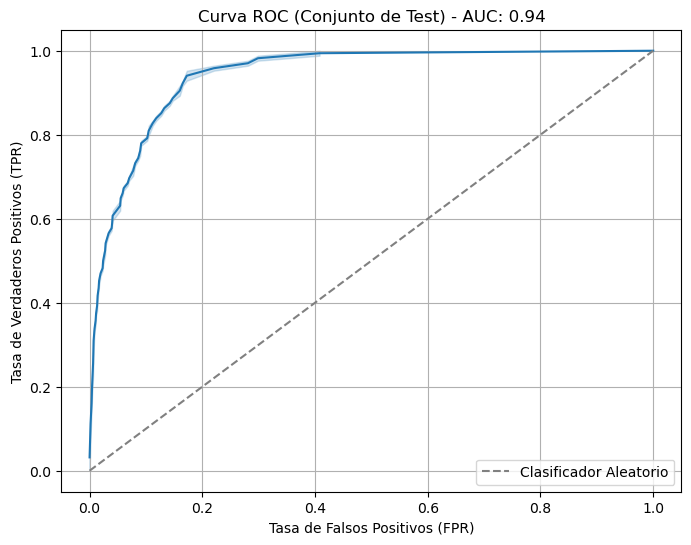

In [15]:
from sklearn.metrics import roc_curve
import seaborn as sns

#Calculo la curva ROC
y_pred_proba = best_logreg.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

#Grafico la curva
plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr, y=tpr)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Clasificador Aleatorio')
plt.title(f'Curva ROC (Conjunto de Test) - AUC: {roc_auc:.2f}')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.grid(True)
plt.legend()
plt.show()

In [16]:
#Imprimo los mejores hiperparametros
print("Best Hyperparameters:", grid_search.best_params_)

Best Hyperparameters: {'C': 100, 'penalty': 'l1'}
